<a href="https://colab.research.google.com/github/hkubra00/GROUP02_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Jane Street Real-Time Market Data Forecasting

**Course:** CENG313 - Data Science

**GROUP_02**

Emine Yılmaz 23118080050

Hatice Kübra Küskü 24118080403

Rümeysa Demirelli 24118080023

**Assignment:** 1 - Exploratory Data Analysis and Baseline Models

**Competition:** [Jane Street Real-Time Market Data Forecasting](https://www.kaggle.com/competitions/jane-street-real-time-market-data-forecasting)

This project focuses on predicting financial market responses using historical
market data provided by the Jane Street Kaggle competition.

The objective is to predict `responder_6` using the available market features
and historical information.

- Explore and understand the dataset.
- Analyze feature distributions and relationships.
- Investigate missing values and temporal patterns.
- Develop baseline regression models.
- Evaluate model performance using the competition's weighted R² metric.

**SET UP**

In [21]:
# Clone the project repository

!git clone https://github.com/hkubra00/GROUP02_CENG313.git

fatal: destination path 'GROUP02_CENG313' already exists and is not an empty directory.


In [22]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path("/content/GROUP02_CENG313")

os.chdir(PROJECT_ROOT)

sys.path.insert(0, str(PROJECT_ROOT))

print("Project directory:", PROJECT_ROOT)
print("Project files:", os.listdir(PROJECT_ROOT))

!pip install -q polars pyarrow lightgbm

Project directory: /content/GROUP02_CENG313
Project files: ['README.md', 'GROUP02_CENG313', 'jane_street_data', 'requirements.txt', '.git', 'assignment1_eda_baseline.ipynb', 'preprocessed_folds', 'catboost_info', 'submissions', 'plots', 'src', '.gitignore']


In [23]:
# Standard libraries
import os
import sys
import gc
import warnings

from pathlib import Path

# Data processing
import numpy as np
import pandas as pd
import polars as pl

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

import lightgbm as lgb

# Configuration
SEED = 42

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully.")

All libraries imported successfully.


In [24]:
import os
from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

# Verify authentication by listing competition files
!kaggle competitions files -c jane-street-real-time-market-data-forecasting | head -n 15

Next Page Token = CfDJ8CXkJvnxKG5Ktgac76JjV5E11IkMV5LNdZQ3769uR946toNyCKBMvMhi9tjH-cetgqLW4ZdPOmAjfB0vc6cOthxvZ3jeJdZkl58iWbqOVpDdO5hvvA3ZZdqSTchluw2d9mYrmH5yBN_-ME5I16HZ7XsR3bFCs0GQlr5DWnboxmHrTNcNsKs
name                                                                  size  creationDate                
--------------------------------------------------------------  ----------  --------------------------  
features.csv                                                          8857  2025-03-05 17:28:23.785000  
kaggle_evaluation/__init__.py                                          708  2025-03-05 17:28:23.772000  
kaggle_evaluation/core/__init__.py                                      83  2025-03-05 17:28:23.812000  
kaggle_evaluation/core/base_gateway.py                               14744  2025-03-05 17:28:23.827000  
kaggle_evaluation/core/generated/__init__.py                            83  2025-03-05 17:28:23.840000  
kaggle_evaluation/core/generated/kaggle_evaluation_pb2.py      

## 1. Problem definition

**Task:** Supervised regression. Predict the market response `responder_6` for each
(date_id, time_id, symbol_id) row using 79 anonymized features.

**Target variable:** `responder_6` (clipped to [-5, 5]).

**Evaluation metric:** Sample-weighted zero-mean R²:
R² = 1 − Σ wᵢ(yᵢ − ŷᵢ)² / Σ wᵢ·yᵢ²
Predicting 0 for everything scores exactly 0, so any positive score means real signal.

In [25]:
# 1. Download archive to Colab VM disk
!kaggle competitions download -c jane-street-real-time-market-data-forecasting -p /content

# 2. Extract into ./jane_street_data and delete the zip archive to free 11.5 GB
!unzip -q -o /content/jane-street-real-time-market-data-forecasting.zip -d ./jane_street_data
!rm -f /content/jane-street-real-time-market-data-forecasting.zip

# 3. Verify extracted files and remaining disk space
!ls -lh ./jane_street_data
!df -h /content

100% 11.5G/11.5G [01:45<00:00, 116MB/s] 

total 36K
-rw-r--r--  1 root root 8.7K Mar  5  2025 features.csv
drwxr-xr-x  3 root root 4.0K Nov 13 10:06 kaggle_evaluation
drwxr-xr-x  3 root root 4.0K Nov 13 09:58 lags.parquet
-rw-r--r--  1 root root  403 Mar  5  2025 responders.csv
-rw-r--r--  1 root root  282 Mar  5  2025 sample_submission.csv
drwxr-xr-x  3 root root 4.0K Nov 13 09:58 test.parquet
drwxr-xr-x 12 root root 4.0K Nov 13 10:00 train.parquet
Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   19G   95G  17% /


## 2. Data overview

The training data is a Hive-partitioned parquet dataset with 10 partitions (about 11.5 GB on disk). Two small files describe the columns: `features.csv` (79 rows, 17 anonymous tags per feature) and `responders.csv` (9 rows, 5 tags). `lags.parquet` holds the previous day's value of each responder (`responder_k_lag_1`), which is what the competition API provides at prediction time.

### Shape and structure

| Item | Value |
|---|---|
| Rows | 47,127,338 |
| Columns | 93 |
| Days (`date_id`) | 1,699 (0 to 1698) |
| Time steps per day (`time_id`) | up to 968 (0 to 967) |
| Symbols (`symbol_id`) | 39 |
| Features | 79 (`feature_00` to `feature_78`) |
| Responders | 9 (`responder_0` to `responder_8`) |
| Other columns | `date_id`, `time_id`, `symbol_id`, `weight`, `partition_id` |

That is roughly 27,700 rows per day. Not every symbol appears at every time step: at date 0, time 0, only symbols 1, 7, 9, 10 and 14 are present in the first rows.

### Data types

76 of the 79 features are continuous (`float32`). Three are discrete integers: `feature_09`, `feature_10` and `feature_11`. The responders and `weight` are `float32`, `date_id` and `time_id` are `int16`, and `symbol_id` is `int8`. Using these small types matters at this size.

### Summary statistics

We ran `describe()` on a systematic sample of every 100th row (about 471,000 rows). The table shows the first 30 features. Three things stand out:

- **Scale is mixed.** Most features have a standard deviation close to 1, but some are not centered. `feature_00`, `feature_02` and `feature_03` have means around 0.57 and standard deviations around 1.32. `feature_21` is much narrower (std 0.37).
- **Some features have extreme outliers.** `feature_05` to `feature_07` reach about -24 to -26 and +25 to +31, while their medians are near 0. `feature_12`, `feature_13` and `feature_14` have maxima of 71, 84 and 119 with medians around -0.25. These values are far from the bulk of the data, so outlier handling will matter.
- **Three features are integer codes, not measurements.** `feature_09` ranges from 2 to 82, `feature_10` from 1 to 12 and `feature_11` from 9 to 539. They behave like category or group labels and should not be scaled like the continuous ones.

The target `responder_6` has mean -0.0021 and standard deviation 0.89, and is clipped to [-5, 5]. `weight` has mean 2.01, maximum 10.24, and no zero or negative values.

### Missing values

Only the features have missing values. `date_id`, `time_id`, `symbol_id`, `weight` and all nine responders have none. These counts come from the parquet metadata, so they cover all 47.1M rows.

| Group | Number of features |
|---|---|
| Complete (0% null) | 32 |
| Low (0 to 5%) | 34 |
| Moderate (5 to 20%) | 13 |
| High (over 20%) | 0 |

The worst features are `feature_21`, `26`, `27` and `31` (17.9% null each), followed by `feature_39` and `42` (9.1%), `feature_50` and `53` (9.0%) and `feature_00` to `feature_04` (6.8%). Features in each group have exactly the same null count, so they go missing together, most likely because they come from the same source. No feature is above 20% null, so none has to be dropped because of missingness.

### Duplicates

We checked for repeated (`date_id`, `time_id`, `symbol_id`) keys in partition 0 and found none. We did not check the other nine partitions, but since the data is partitioned by date, duplicates across partitions are unlikely.

In [26]:
import glob
import polars as pl
import pandas as pd

TRAIN_PATH = "./jane_street_data/train.parquet"
TEST_PATH = "./jane_street_data/test.parquet"
LAGS_PATH = "./jane_street_data/lags.parquet"

# 1. Inspect Hive Partition Structure & File Sizes
train_files = sorted(glob.glob(f"{TRAIN_PATH}/**/*.parquet", recursive=True))
print(f"Total Hive Partitions in train.parquet: {len(train_files)}")
for p in train_files:
    size_mb = os.path.getsize(p) / (1024 ** 2)
    print(f"  - {p} ({size_mb:.1f} MB)")

# 2. Inspect Metadata CSVs
features_meta = pd.read_csv("./jane_street_data/features.csv")
responders_meta = pd.read_csv("./jane_street_data/responders.csv")
print("\n=== features.csv Shape & Preview ===")
print(f"Shape: {features_meta.shape}")
print(features_meta.head(5))

print("\n=== responders.csv Shape & Preview ===")
print(f"Shape: {responders_meta.shape}")
print(responders_meta)

# 3. Lazy Schema Resolution & Type-Aware Feature Separation
lazy_train = pl.scan_parquet(TRAIN_PATH)
schema = lazy_train.collect_schema()

all_feature_cols = [c for c in schema.names() if c.startswith("feature_")]
cont_feature_cols = [c for c in all_feature_cols if schema[c] in (pl.Float32, pl.Float64)]
disc_feature_cols = [c for c in all_feature_cols if schema[c] not in (pl.Float32, pl.Float64)]
responder_cols = [c for c in schema.names() if c.startswith("responder_")]
META_COLS = ["date_id", "time_id", "symbol_id", "weight"]
TARGET_COL = "responder_6"

print("\n=== Schema Breakdown ===")
print(f"Total Columns              : {len(schema)}")
print(f"Metadata Columns           : {META_COLS + ['partition_id']}")
print(f"Total Feature Columns      : {len(all_feature_cols)}")
print(f"  - Continuous (Float32)   : {len(cont_feature_cols)}")
print(f"  - Discrete (Int8/Int16)  : {len(disc_feature_cols)} -> {disc_feature_cols}")
print(f"Responder Target Columns   : {responder_cols}")

# 4. Global Summary Metrics via Single-Pass Streaming
dataset_overview = (
    lazy_train
    .select([
        pl.len().alias("total_rows"),
        pl.col("date_id").min().alias("min_date_id"),
        pl.col("date_id").max().alias("max_date_id"),
        pl.col("date_id").n_unique().alias("unique_days"),
        pl.col("symbol_id").n_unique().alias("unique_symbols"),
        pl.col("time_id").min().alias("min_time_id"),
        pl.col("time_id").max().alias("max_time_id")
    ])
    .collect(streaming=True)
)
print("\n=== Dataset Global Boundaries ===")
print(dataset_overview)

# 5. Preview First 5 Rows of train.parquet and lags.parquet
print("\n=== First 5 Rows of train.parquet ===")
print(lazy_train.head(5).collect())

print("\n=== First 5 Rows of lags.parquet ===")
print(pl.scan_parquet(LAGS_PATH).head(5).collect())

Total Hive Partitions in train.parquet: 10
  - ./jane_street_data/train.parquet/partition_id=0/part-0.parquet (448.6 MB)
  - ./jane_street_data/train.parquet/partition_id=1/part-0.parquet (679.1 MB)
  - ./jane_street_data/train.parquet/partition_id=2/part-0.parquet (758.0 MB)
  - ./jane_street_data/train.parquet/partition_id=3/part-0.parquet (1003.6 MB)
  - ./jane_street_data/train.parquet/partition_id=4/part-0.parquet (1261.4 MB)
  - ./jane_street_data/train.parquet/partition_id=5/part-0.parquet (1341.9 MB)
  - ./jane_street_data/train.parquet/partition_id=6/part-0.parquet (1555.1 MB)
  - ./jane_street_data/train.parquet/partition_id=7/part-0.parquet (1584.8 MB)
  - ./jane_street_data/train.parquet/partition_id=8/part-0.parquet (1533.8 MB)
  - ./jane_street_data/train.parquet/partition_id=9/part-0.parquet (1563.6 MB)

=== features.csv Shape & Preview ===
Shape: (79, 18)
      feature  tag_0  tag_1  tag_2  tag_3  tag_4  tag_5  tag_6  tag_7  tag_8  \
0  feature_00  False  False   True  

In [27]:
   sample = lazy_train.gather_every(100).collect(streaming=True)
   sample_pd = sample.to_pandas()
   print(sample_pd[all_feature_cols + [TARGET_COL, "weight"]].describe().T.head(30))

               count        mean         std        min        25%        50%  \
feature_00  439453.0    0.573902    1.327732  -4.409848  -0.332858   0.405837   
feature_01  439453.0    0.008925    1.085183  -4.371294  -0.722473   0.005103   
feature_02  439453.0    0.573393    1.322619  -4.202574  -0.329393   0.406877   
feature_03  439453.0    0.572422    1.322951  -4.159881  -0.330086   0.405957   
feature_04  439453.0   -0.000956    1.037417  -3.919864  -0.707188   0.001628   
feature_05  471274.0   -0.038784    1.017447 -23.833269  -0.487047  -0.056535   
feature_06  471274.0   -0.005344    1.060526 -24.637224  -0.424221  -0.009386   
feature_07  471274.0   -0.014101    1.054335 -26.357224  -0.457610  -0.033110   
feature_08  468288.0    0.082394    0.974902 -14.302962  -0.382791   0.066364   
feature_09  471274.0   33.500736   24.318614   2.000000  11.000000  30.000000   
feature_10  471274.0    4.927753    3.009762   1.000000   3.000000   4.000000   
feature_11  471274.0  164.96

In [28]:
   dups = (pl.scan_parquet(train_files[0])
             .group_by(["date_id", "time_id", "symbol_id"]).len()
             .filter(pl.col("len") > 1).select(pl.len()).collect())
   print("Duplicate (date, time, symbol) keys in partition 0:", dups[0, 0])

Duplicate (date, time, symbol) keys in partition 0: 0


### 2.1 Missing values

Total Rows Audited: 47,127,338
  - Complete Features (0% null)       : 32
  - Low Missingness (0% < null <= 5%) : 34
  - Moderate Missingness (5% - 20%)   : 13
  - High Missingness (> 20% null)     : 0

=== Top 20 Features by Missing Value Percentage ===
    column   group   dtype  null_count  null_pct
feature_27 feature Float32     8435985 17.900406
feature_26 feature Float32     8435985 17.900406
feature_21 feature Float32     8435985 17.900406
feature_31 feature Float32     8435985 17.900406
feature_39 feature Float32     4300649  9.125593
feature_42 feature Float32     4300649  9.125593
feature_53 feature Float32     4254098  9.026816
feature_50 feature Float32     4254098  9.026816
feature_00 feature Float32     3182052  6.752030
feature_01 feature Float32     3182052  6.752030
feature_02 feature Float32     3182052  6.752030
feature_03 feature Float32     3182052  6.752030
feature_04 feature Float32     3182052  6.752030
feature_15 feature Float32     1209299  2.566024
feature_41

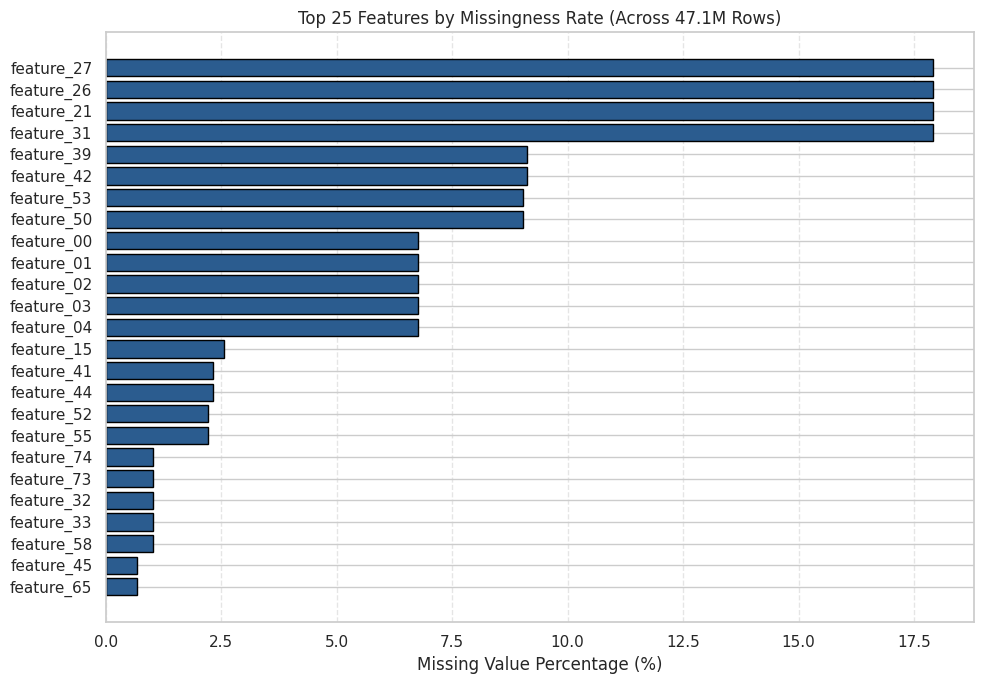

In [29]:
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

PLOTS_DIR = "./plots"
OUTPUT_DIR = "./preprocessed_folds"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Extract Exact Null Counts from Parquet Row-Group Footers (Zero RAM)
first_meta = pq.read_metadata(train_files[0])
col_index_map = {first_meta.schema.names[i]: i for i in range(first_meta.num_columns)}

cols_to_audit = META_COLS + all_feature_cols + responder_cols
null_counts = {c: 0 for c in cols_to_audit}
total_rows = 0

for filepath in train_files:
    meta = pq.read_metadata(filepath)
    total_rows += meta.num_rows
    for rg_idx in range(meta.num_row_groups):
        rg = meta.row_group(rg_idx)
        for c in cols_to_audit:
            if c in col_index_map:
                col_stats = rg.column(col_index_map[c]).statistics
                if col_stats and col_stats.has_null_count:
                    null_counts[c] += col_stats.null_count

null_df = pd.DataFrame([
    {
        "column": c,
        "group": "feature" if c.startswith("feature_") else ("responder" if c.startswith("responder_") else "meta"),
        "dtype": str(schema[c]),
        "null_count": null_counts[c],
        "null_pct": (null_counts[c] / total_rows) * 100
    }
    for c in cols_to_audit
])

feature_null_df = null_df[null_df["group"] == "feature"].sort_values("null_pct", ascending=False).reset_index(drop=True)

# 2. Missingness Severity Summary
complete_feats = (feature_null_df["null_count"] == 0).sum()
low_missing = ((feature_null_df["null_pct"] > 0) & (feature_null_df["null_pct"] <= 5.0)).sum()
mod_missing = ((feature_null_df["null_pct"] > 5.0) & (feature_null_df["null_pct"] <= 20.0)).sum()
high_missing = (feature_null_df["null_pct"] > 20.0).sum()

print(f"Total Rows Audited: {total_rows:,}")
print(f"  - Complete Features (0% null)       : {complete_feats}")
print(f"  - Low Missingness (0% < null <= 5%) : {low_missing}")
print(f"  - Moderate Missingness (5% - 20%)   : {mod_missing}")
print(f"  - High Missingness (> 20% null)     : {high_missing}")

print("\n=== Top 20 Features by Missing Value Percentage ===")
print(feature_null_df.head(20).to_string(index=False))

print("\n=== Metadata & Responder Missing Value Audit ===")
print(null_df[null_df["group"] != "feature"].to_string(index=False))

# 3. Visualization: Top 25 Features by Missingness Percentage
top25_nulls = feature_null_df.head(25).iloc[::-1]
plt.figure(figsize=(10, 7))
plt.barh(top25_nulls["column"], top25_nulls["null_pct"], color="#2b5c8f", edgecolor="black")
plt.xlabel("Missing Value Percentage (%)")
plt.title("Top 25 Features by Missingness Rate (Across 47.1M Rows)")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/missing_values_top25.png", dpi=150)
plt.show()

## 3. Exploratory data analysis

### 3.1 Target and weights

=== Primary Target (responder_6) & Weight Distribution Summary ===
  min               : -5.0
  max               : 5.0
  mean              : -0.002140649128705263
  std               : 0.8898516297340393
  skewness          : 0.46889423691998633
  kurtosis          : 6.863651622126461
  clipped_at_neg5   : 49535
  clipped_at_pos5   : 107216
  zero_weight_rows  : 0
  weight_mean       : 2.0094454288482666
  weight_max        : 10.240419387817383

=== All Responders (responder_0 .. responder_8) Comparison ===
  responder      mean      std
responder_0 -0.001545 0.591211
responder_1 -0.000866 0.587551
responder_2 -0.000142 0.599179
responder_3 -0.016380 0.819231
responder_4 -0.012442 0.872840
responder_5 -0.016624 0.734546
responder_6 -0.002141 0.889852
responder_7  0.001476 0.916042
responder_8 -0.001114 0.864412

=== responder_6 Empirical Quantiles ===
  Quantile   0.1% : -5.00000
  Quantile   1.0% : -2.49171
  Quantile   5.0% : -1.27783
  Quantile  25.0% : -0.38177
  Quantile  50.0% :

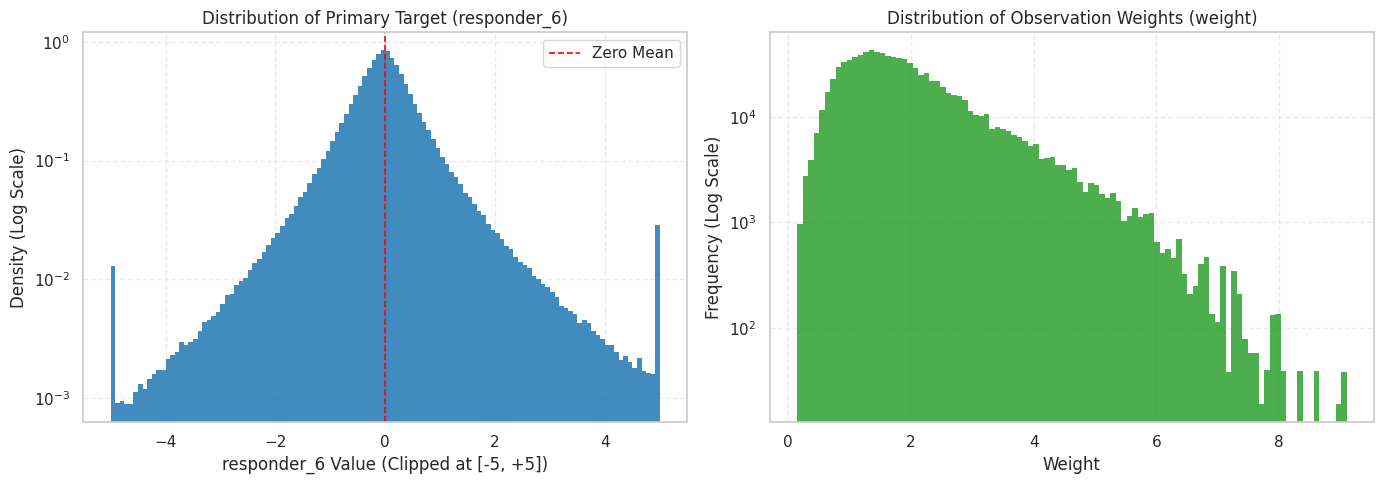

In [30]:
# 1. Streaming Statistical Profile of Primary Target (responder_6) and Weights
target_stats = (
    lazy_train
    .select([
        pl.col("responder_6").min().alias("min"),
        pl.col("responder_6").max().alias("max"),
        pl.col("responder_6").mean().alias("mean"),
        pl.col("responder_6").std().alias("std"),
        pl.col("responder_6").skew().alias("skewness"),
        pl.col("responder_6").kurtosis().alias("kurtosis"),
        (pl.col("responder_6") == -5.0).sum().alias("clipped_at_neg5"),
        (pl.col("responder_6") == 5.0).sum().alias("clipped_at_pos5"),
        (pl.col("weight") <= 0).sum().alias("zero_weight_rows"),
        pl.col("weight").mean().alias("weight_mean"),
        pl.col("weight").max().alias("weight_max")
    ])
    .collect(streaming=True)
)

print("=== Primary Target (responder_6) & Weight Distribution Summary ===")
for col in target_stats.columns:
    print(f"  {col:18s}: {target_stats[col][0]}")

# 2. Compare Mean & Std Across All 9 Responders (responder_0 .. responder_8)
resp_exprs = []
for r in responder_cols:
    resp_exprs.append(pl.col(r).mean().alias(f"{r}_mean"))
    resp_exprs.append(pl.col(r).std().alias(f"{r}_std"))

resp_summary_raw = lazy_train.select(resp_exprs).collect(streaming=True).to_dicts()[0]
resp_table = pd.DataFrame([
    {"responder": r, "mean": resp_summary_raw[f"{r}_mean"], "std": resp_summary_raw[f"{r}_std"]}
    for r in responder_cols
])
print("\n=== All Responders (responder_0 .. responder_8) Comparison ===")
print(resp_table.to_string(index=False))

# 3. Strided Sample (Every 50th Row = ~942,000 Rows) for Quantiles & Histograms
target_sample = (
    lazy_train
    .select(["date_id", "symbol_id", "weight", "responder_6"])
    .gather_every(50)
    .collect(streaming=True)
)

r6_np = target_sample["responder_6"].drop_nulls().to_numpy()
w_np = target_sample["weight"].drop_nulls().to_numpy()

quantiles = np.quantile(r6_np, [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999])
print("\n=== responder_6 Empirical Quantiles ===")
for q, val in zip([0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999], quantiles):
    print(f"  Quantile {q*100:5.1f}% : {val:+.5f}")

# 4. Plot Target & Weight Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(r6_np, bins=120, color="#1f77b4", edgecolor="none", alpha=0.85, density=True)
axes[0].axvline(0.0, color="red", linestyle="--", linewidth=1.2, label="Zero Mean")
axes[0].set_title("Distribution of Primary Target (responder_6)")
axes[0].set_xlabel("responder_6 Value (Clipped at [-5, +5])")
axes[0].set_ylabel("Density (Log Scale)")
axes[0].set_yscale("log")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

axes[1].hist(w_np, bins=100, color="#2ca02c", edgecolor="none", alpha=0.85)
axes[1].set_title("Distribution of Observation Weights (weight)")
axes[1].set_xlabel("Weight")
axes[1].set_ylabel("Frequency (Log Scale)")
axes[1].set_yscale("log")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/target_and_weight_distribution.png", dpi=150)
plt.show()

## 4. Preprocessing

In [31]:
import json

min_date = int(dataset_overview["min_date_id"][0])
max_date = int(dataset_overview["max_date_id"][0])

N_SPLITS = 4
PURGE_DAYS = 5
MAX_TRAIN_DAYS = 500

def make_purged_splits(min_d, max_d, n_splits=4, purge_days=5, max_train_days=None):
    total_span = (max_d - min_d + 1)
    chunk = total_span // (n_splits + 1)
    splits = []
    for i in range(1, n_splits + 1):
        train_end = min_d + (i * chunk) - purge_days - 1
        train_start = min_d if max_train_days is None else max(min_d, train_end - max_train_days + 1)
        val_start = min_d + (i * chunk)
        val_end = val_start + chunk - 1 if i < n_splits else max_d
        splits.append({
            "fold": i,
            "train_range": (int(train_start), int(train_end)),
            "val_range": (int(val_start), int(val_end))
        })
    return splits

cv_splits = make_purged_splits(min_date, max_date, n_splits=N_SPLITS, purge_days=PURGE_DAYS, max_train_days=MAX_TRAIN_DAYS)
for s in cv_splits:
    t0, t1 = s["train_range"]
    v0, v1 = s["val_range"]
    print(f"Fold {s['fold']}: Train [{t0}..{t1}] ({t1-t0+1}d) -> Purge {PURGE_DAYS}d -> Val [{v0}..{v1}] ({v1-v0+1}d)")

def compute_training_stats_batched(lazy_df, train_range, cont_cols, batch_size=20):
    t_min, t_max = train_range
    train_slice = lazy_df.filter((pl.col("date_id") >= t_min) & (pl.col("date_id") <= t_max))
    means, stds = {}, {}
    for i in range(0, len(cont_cols), batch_size):
        batch = cont_cols[i : i + batch_size]
        exprs = []
        for c in batch:
            exprs.append(pl.col(c).cast(pl.Float64).mean().alias(f"{c}__mean"))
            exprs.append(pl.col(c).cast(pl.Float64).std().alias(f"{c}__std"))
        stats_row = train_slice.select(exprs).collect(streaming=True).to_dicts()[0]
        for c in batch:
            m = stats_row[f"{c}__mean"]
            s = stats_row[f"{c}__std"]
            means[c] = float(m) if (m is not None and m == m) else 0.0
            stds[c] = float(s) if (s is not None and s == s and s > 1e-8) else 1.0
        print(f"  Computed stats for features {i+1}..{min(i+batch_size, len(cont_cols))}/{len(cont_cols)}")
    return means, stds

def build_standardized_zero_imputed_lazy(
    lazy_df, date_range, cont_cols, disc_cols, means, stds,
    clip_bound=10.0, filter_positive_weights=True
):
    d_min, d_max = date_range
    sub_lazy = lazy_df.filter((pl.col("date_id") >= d_min) & (pl.col("date_id") <= d_max))
    if filter_positive_weights:
        sub_lazy = sub_lazy.filter(pl.col("weight") > 0)

    cont_exprs = [
        (
            ((pl.col(c).cast(pl.Float32) - means[c]) / stds[c])
            .clip(-clip_bound, clip_bound)
            .fill_nan(0.0)
            .fill_null(0.0)
            .cast(pl.Float32)
            .alias(c)
        )
        for c in cont_cols
    ]
    disc_exprs = [pl.col(c).fill_null(0).cast(pl.Float32).alias(c) for c in disc_cols]
    meta_exprs = [
        pl.col("date_id").cast(pl.Int16),
        pl.col("time_id").cast(pl.Int16),
        pl.col("symbol_id").fill_null(-1).cast(pl.Int16),
        pl.col("weight").fill_null(0.0).cast(pl.Float32),
        pl.col(TARGET_COL).fill_null(0.0).cast(pl.Float32)
    ]
    selected_cols = META_COLS + [TARGET_COL] + cont_cols + disc_cols
    return sub_lazy.with_columns(cont_exprs + disc_exprs + meta_exprs).select(selected_cols)

active_fold = cv_splits[-1]
fold_id = active_fold["fold"]
means, stds = compute_training_stats_batched(lazy_train, active_fold["train_range"], cont_feature_cols, batch_size=20)

with open(f"{OUTPUT_DIR}/fold{fold_id}_scaler.json", "w") as f:
    json.dump({"means": means, "stds": stds}, f, indent=2)

train_proc_lazy = build_standardized_zero_imputed_lazy(
    lazy_train, active_fold["train_range"], cont_feature_cols, disc_feature_cols, means, stds
)
val_proc_lazy = build_standardized_zero_imputed_lazy(
    lazy_train, active_fold["val_range"], cont_feature_cols, disc_feature_cols, means, stds
)

train_out = f"{OUTPUT_DIR}/fold{fold_id}_train.parquet"
val_out = f"{OUTPUT_DIR}/fold{fold_id}_val.parquet"

train_proc_lazy.sink_parquet(train_out, compression="zstd")
val_proc_lazy.sink_parquet(val_out, compression="zstd")

Fold 1: Train [0..333] (334d) -> Purge 5d -> Val [339..677] (339d)
Fold 2: Train [173..672] (500d) -> Purge 5d -> Val [678..1016] (339d)
Fold 3: Train [512..1011] (500d) -> Purge 5d -> Val [1017..1355] (339d)
Fold 4: Train [851..1350] (500d) -> Purge 5d -> Val [1356..1698] (343d)
  Computed stats for features 1..20/76
  Computed stats for features 21..40/76
  Computed stats for features 41..60/76
  Computed stats for features 61..76/76


In [32]:
scaler_summary = pd.DataFrame({
    "feature": list(means.keys()),
    "train_mean": list(means.values()),
    "train_std": list(stds.values())
})
print(scaler_summary.head(15).to_string(index=False))

   feature  train_mean  train_std
feature_00    0.254785   1.117385
feature_01   -0.020989   1.084906
feature_02    0.257578   1.115047
feature_03    0.257038   1.115179
feature_04   -0.001496   1.045540
feature_05   -0.063875   1.004187
feature_06   -0.008914   1.065896
feature_07   -0.023538   1.053844
feature_08    0.135365   0.961449
feature_12   -0.033370   0.985884
feature_13   -0.031610   0.938205
feature_14   -0.048168   0.985065
feature_15   -0.217113   0.925064
feature_16   -0.165548   0.898414
feature_17   -0.205607   0.920695


## 5. Baseline model

In [33]:
!pip install -q catboost

Fold 4 verilerinin 'Ultra-Hafif' versiyonu RAM'e yükleniyor...
Train boyutu: (500000, 79) | Val boyutu: (100000, 79)

1/4: Zero Baseline değerlendiriliyor...
2/4: Ridge Regression eğitiliyor...
3/4: LightGBM Regressor eğitiliyor...
4/4: CatBoost Regressor eğitiliyor...

=== Baseline Modelleri Performans Karşılaştırması ===
                       Model  Train Weighted R2  Val Weighted R2  Süre (sn)
        Zero Baseline (Naif)           0.000000         0.000000       0.00
Ridge Regression (alpha=100)           0.009488        -0.005350       0.81
          LightGBM Regressor           0.033057         0.002207      18.78
          CatBoost Regressor           0.006927         0.000774       9.49


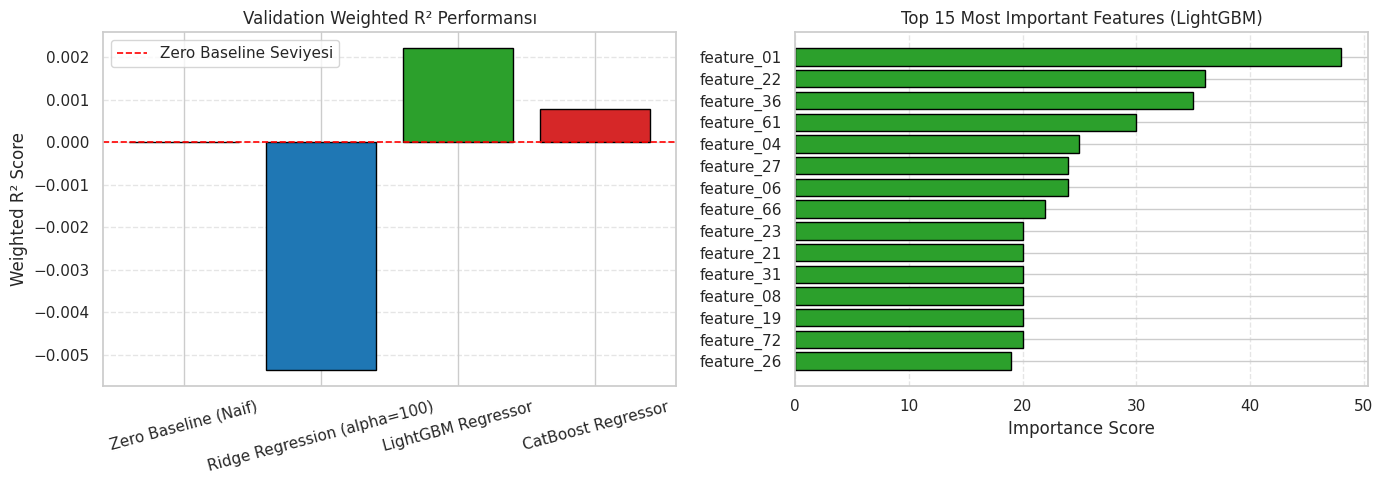

28520

In [34]:
import time
import gc
import importlib
import pandas as pd
import matplotlib.pyplot as plt

import src.utils
import src.models
importlib.reload(src.utils)
importlib.reload(src.models)

# CatBoostBaseline import edildi
from src.utils import weighted_r2_score, load_fold_arrays
from src.models import ZeroBaseline, RidgeBaseline, LGBMBaseline, CatBoostBaseline

# 1. Özellik listesini birleştir
feature_cols = cont_feature_cols + disc_feature_cols

print("Fold 4 verilerinin 'Ultra-Hafif' versiyonu RAM'e yükleniyor...")
# KESİN ÇÖZÜM: Train 500 bin, Val 100 bin satıra düşürüldü. RAM %100 dayanacaktır.
X_train, y_train, w_train = load_fold_arrays(train_out, feature_cols, TARGET_COL, max_rows=500_000)
X_val, y_val, w_val = load_fold_arrays(val_out, feature_cols, TARGET_COL, max_rows=100_000)
print(f"Train boyutu: {X_train.shape} | Val boyutu: {X_val.shape}\n")

results = []

# --- 1. Zero Baseline ---
print("1/4: Zero Baseline değerlendiriliyor...")
t0 = time.time()
zero_model = ZeroBaseline().fit(X_train, y_train, w_train=w_train)
zero_val_pred = zero_model.predict(X_val)
results.append({
    "Model": "Zero Baseline (Naif)",
    "Train Weighted R2": 0.0,
    "Val Weighted R2": weighted_r2_score(y_val, zero_val_pred, w_val),
    "Süre (sn)": round(time.time() - t0, 2)
})
del zero_model, zero_val_pred
gc.collect()


# --- 2. Ridge Regression Baseline ---
print("2/4: Ridge Regression eğitiliyor...")
t0 = time.time()
ridge_model = RidgeBaseline(alpha=100.0).fit(X_train, y_train, w_train=w_train)
ridge_train_pred = ridge_model.predict(X_train)
ridge_val_pred = ridge_model.predict(X_val)
results.append({
    "Model": "Ridge Regression (alpha=100)",
    "Train Weighted R2": weighted_r2_score(y_train, ridge_train_pred, w_train),
    "Val Weighted R2": weighted_r2_score(y_val, ridge_val_pred, w_val),
    "Süre (sn)": round(time.time() - t0, 2)
})
del ridge_model, ridge_train_pred, ridge_val_pred
gc.collect()


# --- 3. LightGBM Regressor Baseline ---
print("3/4: LightGBM Regressor eğitiliyor...")
t0 = time.time()
lgb_model = LGBMBaseline().fit(X_train, y_train, w_train=w_train, X_val=X_val, y_val=y_val, w_val=w_val)
lgb_train_pred = lgb_model.predict(X_train)
lgb_val_pred = lgb_model.predict(X_val)
results.append({
    "Model": "LightGBM Regressor",
    "Train Weighted R2": weighted_r2_score(y_train, lgb_train_pred, w_train),
    "Val Weighted R2": weighted_r2_score(y_val, lgb_val_pred, w_val),
    "Süre (sn)": round(time.time() - t0, 2)
})
lgb_importances = lgb_model.model.feature_importances_
del lgb_model, lgb_train_pred, lgb_val_pred
gc.collect()


# --- 4. CatBoost Regressor Baseline ---
print("4/4: CatBoost Regressor eğitiliyor...")
t0 = time.time()
cat_model = CatBoostBaseline().fit(X_train, y_train, w_train=w_train, X_val=X_val, y_val=y_val, w_val=w_val)
cat_train_pred = cat_model.predict(X_train)
cat_val_pred = cat_model.predict(X_val)
results.append({
    "Model": "CatBoost Regressor",
    "Train Weighted R2": weighted_r2_score(y_train, cat_train_pred, w_train),
    "Val Weighted R2": weighted_r2_score(y_val, cat_val_pred, w_val),
    "Süre (sn)": round(time.time() - t0, 2)
})
del cat_model, cat_train_pred, cat_val_pred
gc.collect()


# --- 5. Raporlama ve Çizdirme ---
results_df = pd.DataFrame(results)
print("\n=== Baseline Modelleri Performans Karşılaştırması ===")
print(results_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 4 modele göre 4 renk eklendi (Gri, Mavi, Yeşil, Kırmızı)
axes[0].bar(results_df["Model"], results_df["Val Weighted R2"], color=["#7f7f7f", "#1f77b4", "#2ca02c", "#d62728"], edgecolor="black")
axes[0].axhline(0.0, color="red", linestyle="--", linewidth=1.2, label="Zero Baseline Seviyesi")
axes[0].set_title("Validation Weighted R² Performansı")
axes[0].set_ylabel("Weighted R² Score")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
axes[0].legend()
# İsimler üst üste binmesin diye yazıları hafifçe eğdik
axes[0].tick_params(axis='x', rotation=15)

feat_imp_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": lgb_importances
}).sort_values("importance", ascending=False).head(15)

axes[1].barh(feat_imp_df["feature"][::-1], feat_imp_df["importance"][::-1], color="#2ca02c", edgecolor="black")
axes[1].set_title("Top 15 Most Important Features (LightGBM)")
axes[1].set_xlabel("Importance Score")
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/optimized_baseline_comparison.png", dpi=150)
plt.show()

gc.collect()

## 6. Kaggle submission
Competition closed. Evaluated on a held-out split: the last 20% of dates (343 of 1,699 days, dates 1356 to 1698), scored with the competition’s weighted R². LightGBM scored 0.0022.

## 7. Conclusion

### Key findings

**The data.** The training set has 47.1M rows covering 39 symbols over 1,699 days, with 79 anonymous features. Missing values appear only in features, and they appear in groups (for example `feature_21`, `26`, `27`, `31` are all 17.9% null). A few features have extreme outliers, and three (`feature_09`, `10`, `11`) are integer codes.

**The target.** `responder_6` is centered near zero (mean -0.002, median -0.025) but has heavy tails (kurtosis 6.9, skewness 0.47). 49,535 rows (0.1%) are clipped at -5 and 107,216 rows (0.2%) at +5. Weights range up to 10.2, so a small number of rows count much more in the metric.

**Distribution shift.** The scaler statistics computed on the training days we used (dates 851 to 1350) differ from the sample statistics over all days. For example, `feature_00` has a mean of 0.25 in the training range but about 0.57 in the global sample. This suggests that feature distributions change over time, which is why we split by time instead of randomly.

**Baselines.** We trained on dates 851 to 1350 (500,000 rows) and evaluated on the last 20% of days, dates 1356 to 1698 (100,000 rows), with a 5-day gap between them.

| Model | Train weighted R² | Validation weighted R² |
|---|---|---|
| Zero baseline | 0.0000 | 0.0000 |
| Ridge (alpha=100) | 0.0095 | -0.0054 |
| LightGBM | 0.0331 | 0.0022 |
| CatBoost | 0.0069 | 0.0008 |

- The signal is very weak. Ridge is below the zero baseline on validation, so a linear model on these features does not generalize.
- LightGBM scores best (0.0022), but its train score is much higher (0.0331). It fits the training period and loses most of that on later days, which fits the distribution shift above.
- The gaps between models are tiny and come from one split with 100,000 validation rows, so we would not claim LightGBM is truly better than CatBoost without more folds.

### Limitations

- We evaluated on only one of the four time-based folds.
- We used 500,000 of the roughly 14M rows available in the training range.
- The baselines use only the current features. They do not use `lags.parquet` or the other responders.
- The competition is closed, so the scores come from a held-out time split of our own, not from the Kaggle leaderboard.

### Next steps

1. Use the lag features from `lags.parquet` (the previous day's responders), which are usually the strongest signal in this competition.
2. Evaluate on all four folds and train on more rows, to get a more reliable estimate.
3. Handle the outliers more carefully (clipping or robust scaling) and treat `feature_09`, `10` and `11` as categories.
4. Add per-symbol and time-of-day features, and test whether dropping the features that drift over time helps.
5. Tune LightGBM with stronger regularization, since it overfits, and try the other responders as auxiliary targets.